#### Mini Project - IronKaggle

In [2]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import warnings                                              
from sklearn.exceptions import DataConversionWarning          
warnings.filterwarnings(action='ignore', category=DataConversionWarning)

In [3]:
houses = pd.read_csv("king_ country_ houses_aa.csv", encoding='latin1')
houses.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [4]:
print(houses.shape)
print(houses.info())
print(houses.describe())
print(houses.nunique())


(21613, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64

In [5]:
cat = houses[["id", "date", "floors",'zipcode','waterfront', 'view','condition','grade']]
num = houses.drop(columns=["id", "date","floors",'zipcode','waterfront', 'view','condition','grade'])

In [6]:
corr_matrix = num.corr().abs()
corr_matrix

,price,bedrooms,bathrooms,sqft_living,sqft_lot,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15
price,1.000000,0.308350,0.525138,0.702035,0.089661,0.605567,0.323816,0.054012,0.126434,0.307003,0.021626,0.585379,0.082447
bedrooms,0.308350,1.000000,0.515884,0.576671,0.031703,0.477600,0.303093,0.154178,0.018841,0.008931,0.129473,0.391638,0.029244
bathrooms,0.525138,0.515884,1.000000,0.754665,0.087740,0.685342,0.283770,0.506019,0.050739,0.024573,0.223042,0.568634,0.087175
sqft_living,0.702035,0.576671,0.754665,1.000000,0.172826,0.876597,0.435043,0.318049,0.055363,0.052529,0.240223,0.756420,0.183286
sqft_lot,0.089661,0.031703,0.087740,0.172826,1.000000,0.183512,0.015286,0.053080,0.007644,0.085683,0.229521,0.144608,0.718557
sqft_above,0.605567,0.477600,0.685342,0.876597,0.183512,1.000000,0.051943,0.423898,0.023285,0.000816,0.343803,0.731870,0.194050
sqft_basement,0.323816,0.303093,0.283770,0.435043,0.015286,0.051943,1.000000,0.133124,0.071323,0.110538,0.144765,0.200355,0.017276
yr_built,0.054012,0.154178,0.506019,0.318049,0.053080,0.423898,0.133124,1.000000,0.224874,0.148122,0.409356,0.326229,0.070958
yr_renovated,0.126434,0.018841,0.050739,0.055363,0.007644,0.023285,0.071323,0.224874,1.000000,0.029398,0.068372,0.002673,0.007854
lat,0.307003,0.008931,0.024573,0.052529,0.085683,0.000816,0.110538,0.148122,0.029398,1.000000,0.135512,0.048858,0.086419


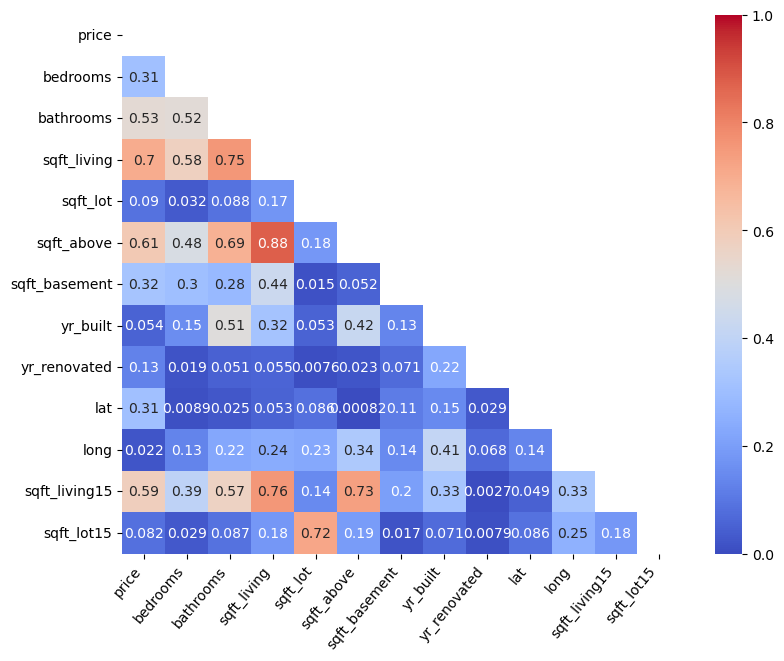

In [7]:
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
plt.figure(figsize=(9,7))
sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='coolwarm', vmin=0, vmax=1)
plt.xticks(rotation=50, ha='right')
plt.show()

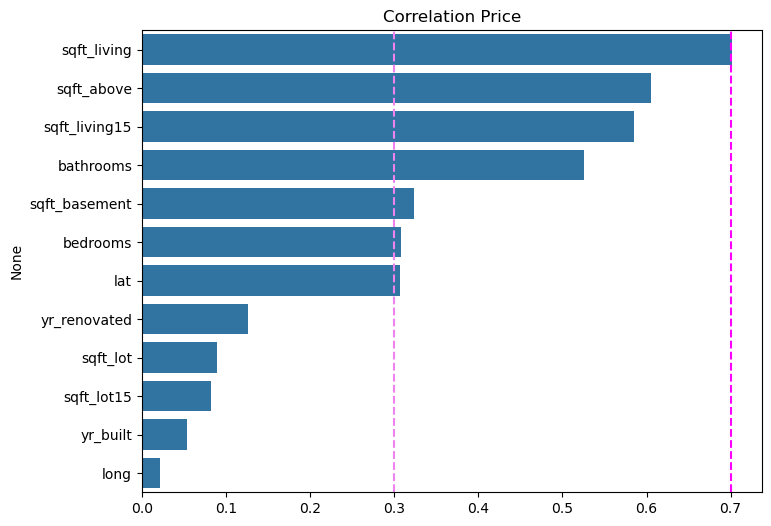

In [8]:
price_corr = corr_matrix['price'].drop("price").sort_values(ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(x=price_corr.values,
            y=price_corr.index)

plt.axvline(0.3, color='violet', linestyle='--')
plt.axvline(0.7, color='magenta', linestyle='--')

plt.title("Correlation Price")
plt.tight_layout
plt.show()


In [9]:
print(houses.isnull().sum())
print(houses.shape)

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64
(21613, 21)


In [10]:
print(num.isnull().sum())
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.90)]
print(f"Suggested columns to drop due to high collinearity: {to_drop}")

price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64
Suggested columns to drop due to high collinearity: []


In [11]:
cat.value_counts()

id          date             floors  zipcode  waterfront  view  condition  grade
1000102     20140916T000000  2.0     98002    0           0     3          7        1
6324000090  20150511T000000  1.0     98116    0           0     1          6        1
6329000380  20140619T000000  1.0     98146    0           0     3          7        1
6329000190  20140729T000000  1.0     98146    1           4     3          8        1
6329000185  20150329T000000  1.5     98146    1           4     3          8        1
                                                                                   ..
2767603649  20140730T000000  3.0     98107    0           0     3          8        1
2767603615  20140903T000000  3.0     98107    0           0     3          8        1
2767603612  20150113T000000  3.0     98107    0           0     3          8        1
            20140512T000000  3.0     98107    0           0     3          8        1
9900000190  20141030T000000  1.0     98166    0           0

In [12]:
print(houses['floors'].unique())
print(houses['waterfront'].unique())
print(houses['view'].unique())
print(houses['condition'].unique())
print(houses['grade'].unique())

[1.  2.  1.5 3.  2.5 3.5]
[0 1]
[0 3 4 2 1]
[3 5 4 1 2]
[ 7  6  8 11  9  5 10 12  4  3 13  1]


In [13]:
houses_low = houses[houses['price'] < 650000]
houses_high = houses[houses['price'] >= 650000]
print(houses_high.describe())

                 id         price     bedrooms    bathrooms   sqft_living  \
count  5.324000e+03  5.324000e+03  5324.000000  5324.000000   5324.000000   
mean   4.513251e+09  9.906619e+05     3.824005     2.676606   3005.195718   
std    2.936512e+09  4.777454e+05     0.896912     0.792677   1028.645889   
min    3.600072e+06  6.500000e+05     0.000000     0.000000    890.000000   
25%    1.939075e+09  7.250000e+05     3.000000     2.250000   2330.000000   
50%    3.885805e+09  8.300000e+05     4.000000     2.500000   2890.000000   
75%    7.303650e+09  1.050000e+06     4.000000     3.250000   3510.000000   
max    9.839301e+09  7.700000e+06    10.000000     8.000000  13540.000000   

           sqft_lot       floors   waterfront         view    condition  \
count  5.324000e+03  5324.000000  5324.000000  5324.000000  5324.000000   
mean   2.127395e+04     1.713186     0.025169     0.627911     3.462434   
std    6.022981e+04     0.496188     0.156653     1.198337     0.687437   
min   

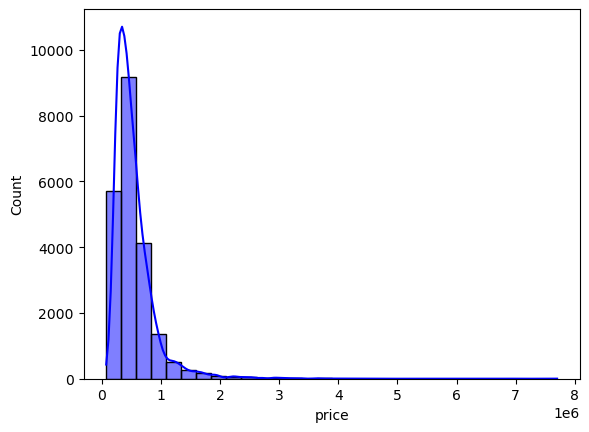

In [14]:
sns.histplot (data=houses, x='price', bins=30, kde=True, color='blue')
plt.show()

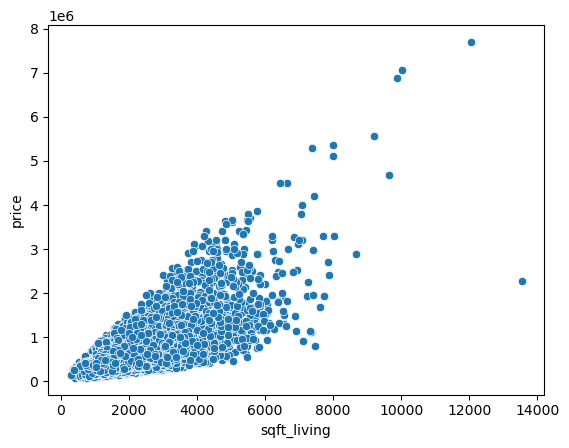

In [15]:
sns.scatterplot(data=houses, x='sqft_living', y='price')
plt.show()

In [16]:
def outlier_price(houses):
    Q1 = houses['price'].quantile(0.25)
    Q3 = houses['price'].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
  
    filtered = houses[(houses['price'] >= lower_bound) & (houses['price'] <= upper_bound)].copy()
    return(filtered)

houses_clean = outlier_price(houses)
print(houses_clean)

               id             date     price  bedrooms  bathrooms  \
0      7129300520  20141013T000000  221900.0         3       1.00   
1      6414100192  20141209T000000  538000.0         3       2.25   
2      5631500400  20150225T000000  180000.0         2       1.00   
3      2487200875  20141209T000000  604000.0         4       3.00   
4      1954400510  20150218T000000  510000.0         3       2.00   
...           ...              ...       ...       ...        ...   
21608   263000018  20140521T000000  360000.0         3       2.50   
21609  6600060120  20150223T000000  400000.0         4       2.50   
21610  1523300141  20140623T000000  402101.0         2       0.75   
21611   291310100  20150116T000000  400000.0         3       2.50   
21612  1523300157  20141015T000000  325000.0         2       0.75   

       sqft_living  sqft_lot  floors  waterfront  view  ...  grade  \
0             1180      5650     1.0           0     0  ...      7   
1             2570      7242   

In [17]:
houses_low.loc[:,'group'] = 'low'
houses_high.loc[:,'group'] = 'high'
houses_comb = pd.concat([houses_low, houses_high])

C:\Users\Asus\AppData\Local\Temp\ipykernel_12800\2438569279.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  houses_low.loc[:,'group'] = 'low'
C:\Users\Asus\AppData\Local\Temp\ipykernel_12800\2438569279.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  houses_high.loc[:,'group'] = 'high'


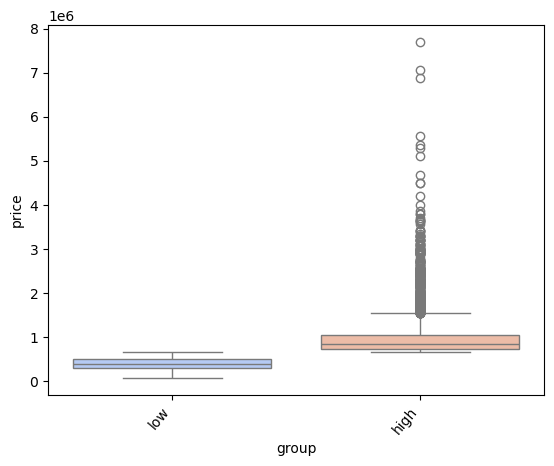

In [18]:
sns.boxplot(
    data= houses_comb, 
    x="group", 
    y="price", 
    hue='group',
    palette="coolwarm",
 )
plt.xticks(rotation=50, ha='right')
plt.show()

In [19]:
def outlier_price(houses):
    Q1 = houses_high['price'].quantile(0.25)
    Q3 = houses_high['price'].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
  
    filtered = houses_high[(houses_high['price'] >= lower_bound) & (houses_high['price'] <= upper_bound)].copy()
    return(filtered)

hh_clean = outlier_price(houses_high)
print(hh_clean)

               id             date      price  bedrooms  bathrooms  \
5      7237550310  20140512T000000  1225000.0         4       4.50   
10     1736800520  20150403T000000   662500.0         3       2.50   
15     9297300055  20150124T000000   650000.0         4       3.00   
26     1794500383  20140626T000000   937000.0         3       1.75   
27     3303700376  20141201T000000   667000.0         3       1.00   
...           ...              ...        ...       ...        ...   
21593  8672200110  20150317T000000  1088000.0         5       3.75   
21596  7502800100  20140813T000000   679950.0         5       2.75   
21599  7202300110  20140915T000000   810000.0         4       3.00   
21600   249000205  20141015T000000  1537000.0         5       3.75   
21606  7936000429  20150326T000000  1007500.0         4       3.50   

       sqft_living  sqft_lot  floors  waterfront  view  ...  sqft_above  \
5             5420    101930     1.0           0     0  ...        3890   
10       

In [20]:
houses_clean = houses_clean.drop(columns=['id'])

In [21]:
houses_clean['zipcode'].unique()

array([98178, 98125, 98028, 98136, 98074, 98003, 98198, 98146, 98038,
       98007, 98115, 98107, 98126, 98019, 98103, 98002, 98133, 98092,
       98030, 98119, 98112, 98052, 98027, 98117, 98058, 98001, 98056,
       98166, 98053, 98023, 98148, 98105, 98042, 98008, 98059, 98122,
       98144, 98004, 98005, 98034, 98075, 98116, 98010, 98118, 98199,
       98040, 98032, 98045, 98102, 98077, 98108, 98168, 98177, 98065,
       98029, 98006, 98109, 98022, 98033, 98155, 98024, 98011, 98031,
       98106, 98070, 98072, 98188, 98014, 98055, 98039])

In [22]:
zip_avg = houses.groupby('zipcode')['price'].mean()
zip_avg

zipcode
98001    2.808047e+05
98002    2.342840e+05
98003    2.941113e+05
98004    1.355927e+06
98005    8.101649e+05
             ...     
98177    6.761854e+05
98178    3.106128e+05
98188    2.890783e+05
98198    3.028789e+05
98199    7.918208e+05
Name: price, Length: 70, dtype: float64

In [23]:
ExpensiveZip = houses_clean.groupby('zipcode')['price'].mean()
ExpensiveZip = ExpensiveZip.sort_values(ascending=False)
top20 = ExpensiveZip.head(20)
top20_categories = top20.index
houses_clean['zip_group'] = houses_clean['zipcode'].apply(lambda x: x if x in top20_categories else 'other')
print(houses_clean['zip_group'].value_counts())

zip_group
other    15373
98052      563
98115      558
98074      423
98006      405
98053      380
98033      369
98075      330
98029      313
98199      273
98077      188
98105      178
98112      170
98040      165
98119      154
98004      154
98005      153
98007      137
98102       89
98109       86
98039        6
Name: count, dtype: int64


In [24]:
CountHouses = houses_clean.groupby('zipcode')['price'].count()
CountHouses = CountHouses.sort_values(ascending=False)
CountHouses

zipcode
98103    590
98038    588
98052    563
98115    558
98042    548
        ... 
98102     89
98109     86
98024     74
98148     57
98039      6
Name: price, Length: 70, dtype: int64

In [25]:
Over250 = CountHouses[CountHouses>=250]
Over250_categories = Over250.index
houses_clean['zip_count'] = houses_clean['zipcode'].apply(lambda x: x if x in Over250_categories else 'other')
print(houses_clean['zip_count'].value_counts())
print(houses_clean['zip_count'].nunique())

zip_count
other    3910
98103     590
98038     588
98052     563
98115     558
98042     548
98117     543
98034     526
98118     502
98023     497
98133     494
98058     453
98059     452
98155     440
98074     423
98006     405
98056     403
98125     402
98027     394
98053     380
98033     369
98001     362
98126     354
98092     351
98106     335
98075     330
98144     319
98116     313
98029     313
98065     305
98146     283
98028     282
98003     280
98198     278
98031     274
98199     273
98122     271
98168     269
98055     268
98008     266
98072     265
98107     262
98178     261
98136     257
98030     256
Name: count, dtype: int64
45


In [26]:
houses_clean = houses_clean.drop(columns=['zipcode'])
houses_clean.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,zip_group,zip_count
0,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,...,1180,0,1955,0,47.5112,-122.257,1340,5650,other,98178
1,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,...,2170,400,1951,1991,47.7210,-122.319,1690,7639,other,98125
2,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,...,770,0,1933,0,47.7379,-122.233,2720,8062,other,98028
3,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,...,1050,910,1965,0,47.5208,-122.393,1360,5000,other,98136
4,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,...,1680,0,1987,0,47.6168,-122.045,1800,7503,98074,98074


In [27]:
houses_clean['date'] = pd.to_datetime(houses_clean['date'])
houses_clean['year'] = houses_clean['date'].dt.year
houses_clean['quarter'] = houses_clean['date'].dt.quarter

houses_clean = houses_clean.drop(columns=['date'])
houses_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20467 entries, 0 to 21612
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          20467 non-null  float64
 1   bedrooms       20467 non-null  int64  
 2   bathrooms      20467 non-null  float64
 3   sqft_living    20467 non-null  int64  
 4   sqft_lot       20467 non-null  int64  
 5   floors         20467 non-null  float64
 6   waterfront     20467 non-null  int64  
 7   view           20467 non-null  int64  
 8   condition      20467 non-null  int64  
 9   grade          20467 non-null  int64  
 10  sqft_above     20467 non-null  int64  
 11  sqft_basement  20467 non-null  int64  
 12  yr_built       20467 non-null  int64  
 13  yr_renovated   20467 non-null  int64  
 14  lat            20467 non-null  float64
 15  long           20467 non-null  float64
 16  sqft_living15  20467 non-null  int64  
 17  sqft_lot15     20467 non-null  int64  
 18  zip_group  

In [28]:
houses_dummy = pd.get_dummies(houses_clean, drop_first=True)
houses_dummy.dtypes[houses_dummy.dtypes == 'object']


Series([], dtype: object)

In [29]:
houses_dummy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20467 entries, 0 to 21612
Data columns (total 84 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   price            20467 non-null  float64
 1   bedrooms         20467 non-null  int64  
 2   bathrooms        20467 non-null  float64
 3   sqft_living      20467 non-null  int64  
 4   sqft_lot         20467 non-null  int64  
 5   floors           20467 non-null  float64
 6   waterfront       20467 non-null  int64  
 7   view             20467 non-null  int64  
 8   condition        20467 non-null  int64  
 9   grade            20467 non-null  int64  
 10  sqft_above       20467 non-null  int64  
 11  sqft_basement    20467 non-null  int64  
 12  yr_built         20467 non-null  int64  
 13  yr_renovated     20467 non-null  int64  
 14  lat              20467 non-null  float64
 15  long             20467 non-null  float64
 16  sqft_living15    20467 non-null  int64  
 17  sqft_lot15       

In [30]:
from sklearn.model_selection import train_test_split

# Your code here:
X = houses_dummy.drop(columns=['price'])
y = houses_dummy['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, balanced_accuracy_score
from sklearn.datasets import make_regression, make_classification

In [32]:
reg_model = LinearRegression().fit(X_train,y_train)
score = r2_score(y_test, model.predict(X_test))
train_preds = reg_model.predict(X_train)
test_preds = reg_model.predict(X_test)

print(f"R-squared: {score:.4}")
print(f"R2 Train score: {r2_score(y_train, train_preds):.4f}")
print(f"Train MSE: {mean_squared_error(y_train, train_preds):.4f}")
print(f"Test MSE: {mean_squared_error(y_test, test_preds):.4f}")
print(f"Train MAE: {mean_absolute_error(y_train, train_preds):.4f}")
print(f"Test MAE: {mean_absolute_error(y_test, test_preds):.4f}")


NameError: name 'model' is not defined

In [ ]:
pd.DataFrame({
    'actual': y_test,
    'predictions': test_preds,
    'error': test_preds - y_test
})

,actual,predictions,error
16607,420000.0,671328.195053,251328.195053
15557,230000.0,312023.996987,82023.996987
1285,270000.0,245825.864579,-24174.135421
5964,807000.0,725123.348620,-81876.651380
7051,225000.0,211611.882994,-13388.117006
...,...,...,...
12998,565000.0,560827.414714,-4172.585286
12561,1085500.0,809371.543981,-276128.456019
5286,241500.0,348921.440832,107421.440832
16069,535000.0,557651.935373,22651.935373


In [ ]:
print(f"Mean Absolute Error (MAE): {mean_absolute_error(y_test, y_pred):.2f}")

Mean Absolute Error (MAE): 71858.01


In [ ]:
houses_low = houses_dummy[houses_dummy['price'] < 650000]
houses_high = houses_dummy[houses_dummy['price'] >= 650000]
print(houses_high.describe())

              price     bedrooms    bathrooms  sqft_living      sqft_lot  \
count  4.178000e+03  4178.000000  4178.000000  4178.000000  4.178000e+03   
mean   8.051225e+05     3.747008     2.521482  2747.854955  2.053300e+04   
std    1.193495e+05     0.872475     0.686559   789.870004  6.040483e+04   
min    6.500000e+05     0.000000     0.000000   890.000000  5.200000e+02   
25%    7.050000e+05     3.000000     2.250000  2210.000000  5.040000e+03   
50%    7.800000e+05     4.000000     2.500000  2710.000000  8.016500e+03   
75%    8.800000e+05     4.000000     2.750000  3240.000000  1.274900e+04   
max    1.127500e+06    10.000000     6.750000  7480.000000  1.651359e+06   

            floors   waterfront         view    condition        grade  \
count  4178.000000  4178.000000  4178.000000  4178.000000  4178.000000   
mean      1.683700     0.007659     0.433940     3.461944     8.556486   
std       0.494949     0.087191     0.990289     0.681583     1.067864   
min       1.000000 

In [ ]:
houses_low.loc[:,'group'] = 'low'
houses_high.loc[:,'group'] = 'high'
houses_comb = pd.concat([houses_low, houses_high])

C:\Users\Asus\AppData\Local\Temp\ipykernel_13852\2438569279.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  houses_low.loc[:,'group'] = 'low'
C:\Users\Asus\AppData\Local\Temp\ipykernel_13852\2438569279.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  houses_high.loc[:,'group'] = 'high'


In [ ]:
houses_comb.head(5)

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,...,zip_count_98136,zip_count_98144,zip_count_98146,zip_count_98155,zip_count_98168,zip_count_98178,zip_count_98198,zip_count_98199,zip_count_other,group
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,...,False,False,False,False,False,True,False,False,False,low
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,...,False,False,False,False,False,False,False,False,False,low
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,...,False,False,False,False,False,False,False,False,False,low
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,...,True,False,False,False,False,False,False,False,False,low
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,...,False,False,False,False,False,False,False,False,False,low


In [ ]:
from sklearn.tree import DecisionTreeRegressor
# Create decision tree classifer object
regr = DecisionTreeRegressor()

# Train regression tree model
model2 = regr.fit(X_train, y_train)

# Score the model
model2.score(X_test, y_test)

y_pred = regr.predict(X_test)

print(f"R2 Test score: {r2_score(y_test, y_pred):.4}")
print(f"R2 Train score: {r2_score(y_train, train_preds):.4f}")
print(f"Train MSE: {mean_squared_error(y_train, train_preds):.4f}")
print(f"Test MSE: {mean_squared_error(y_test, y_pred):.4f}")
print(f"Train MAE: {mean_absolute_error(y_train, train_preds):.4f}")
print(f"Test MAE: {mean_absolute_error(y_test, test_preds):.4f}")

R2 Test score: 0.7213
R2 Train score: 0.5219
Train MSE: 20967797298.3574
Test MSE: 11605039134.7660
Train MAE: 103670.1386
Test MAE: 104067.7277
